# Modelo final e conclusões

## Importando bibliotecas e dados

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.knn_utils import metricas, escalar

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

In [2]:
train_df = pd.read_csv("../data/processed/train.csv", index_col="id")
test_df = pd.read_csv("../data/processed/test.csv", index_col="id")
X_train, y_train = train_df.drop(columns="classe"), train_df["classe"]
X_test, y_test = test_df.drop(columns="classe"), test_df["classe"]

## Avaliação da hipótese indutiva e escolha final

### Configuração final

```
Escalonamento: MinMaxScaler (ajustado somente no treino)
k: 15
Métrica de distância: Minkowski
p: 2 (euclidiana)
weights: uniform
```

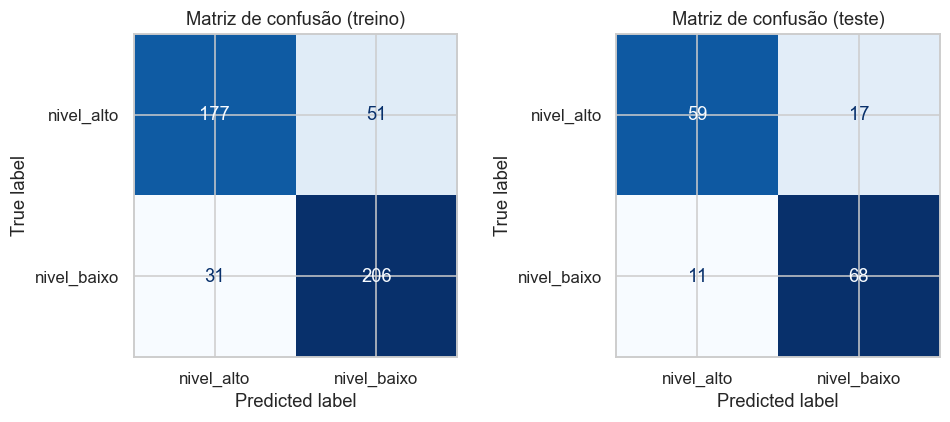

In [3]:
A_tr, A_te = escalar("minmax", X_train, X_test)
final = KNeighborsClassifier(n_neighbors=15, metric="minkowski", p=2, weights="uniform")
final.fit(A_tr, y_train)

pred_tr = final.predict(A_tr)
pred_te = final.predict(A_te)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (yy, pp, nome) in zip(axes, [(y_train, pred_tr, "treino"), (y_test, pred_te, "teste")]):
    ConfusionMatrixDisplay.from_predictions(yy, pp, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusão ({nome})")
plt.tight_layout()
plt.show()

In [4]:
resultado = pd.DataFrame({"treino": metricas(y_train, pred_tr), "teste": metricas(y_test, pred_te)})
resultado.index = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
resultado.to_csv("../data/processed/modelo_final.csv", index_label="metrica")


import os, joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
os.makedirs("../models", exist_ok=True)
modelo_final = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=15, metric="minkowski", p=2, weights="uniform"))
modelo_final.fit(X_train, y_train)
joblib.dump(modelo_final, "../models/modelo_final.joblib")

resultado

,treino,teste
Accuracy,0.8237,0.8194
Precision (macro),0.8263,0.8214
Recall (macro),0.8228,0.8185
F1 (macro),0.8230,0.8187


In [5]:
print("Relatório por classe (teste)")
print(classification_report(y_test, pred_te, digits=3))

Relatório por classe (teste)
              precision    recall  f1-score   support

  nivel_alto      0.843     0.776     0.808        76
 nivel_baixo      0.800     0.861     0.829        79

    accuracy                          0.819       155
   macro avg      0.821     0.819     0.819       155
weighted avg      0.821     0.819     0.819       155



In [6]:
baseline = pd.read_csv("../data/processed/baseline.csv", index_col="modelo").loc["A - dados originais"]
comp_final = pd.DataFrame({
    "baseline (k=5, sem escala)": baseline[["acc_teste", "prec_teste", "rec_teste", "f1_teste"]].tolist(),
    "modelo final": list(metricas(y_test, pred_te).values()),
}).T
comp_final.columns = ["Accuracy", "Precision", "Recall", "F1"]
comp_final

,Accuracy,Precision,Recall,F1
"baseline (k=5, sem escala)",0.6129,0.6127,0.6125,0.6125
modelo final,0.8194,0.8214,0.8185,0.8187


### A hipótese do K-NN vale para este dataset?

* Em parte. Com escalonamento, o F1 chegou a ~0,82, acima do acaso (0,50) e do baseline (0,61).
* O resultado depende da escala e das variáveis: sem escala, o F1 foi 0,61; com atributos de ruído, caiu para 0,63.
* As classes apresentam sobreposição, limitando o desempenho do modelo.
* O K-NN funciona razoavelmente bem, mas depende de escalonamento e da ausência de atributos irrelevantes.

### Justificativa da escolha

* Escolhemos configuração A pela estabilidade, não pelo maior F1 de teste.
* MinMaxScaler foi utilizado para evitar que uma variável dominasse a distância.
* k = 15 apresentou bom equilíbrio, com gap de 0,004 e validação cruzada de 0,782.
* A Euclidiana e a votação uniforme foram mantidas pela estabilidade dos resultados.
* A configuração B teve F1 de teste 0,006 maior, mas gap de 0,175, indicando maior variância.

### Pergunta final

* O segundo modelo (k = 15)tende a generalizar melhor por apresentar treino e teste muito próximos.
* Com k pequeno, o modelo tem baixo viés e alta variância, podendo memorizar os dados.
* Com k = 15, há um pouco mais de viés, mas menor variância e maior estabilidade.
* Com k muito grande, ocorre underfitting e o desempenho cai.
 
